<a href="https://colab.research.google.com/github/Roshan-aiml/BUILD-AND-DEPLOY/blob/main/EXP_5_K_MEANS_CLUSTERING_AND_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Part 1: K-Means Clustering ---

Original K-Means Dataset Head:
   Feature_1  Feature_2
0  -7.155244  -7.390016
1  -7.395875  -7.110843
2  -2.015671   8.281780
3   4.509270   2.632436
4  -8.102502  -7.484961


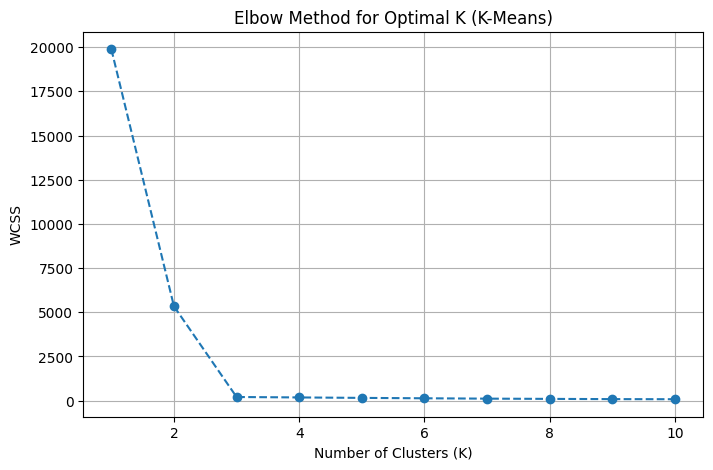

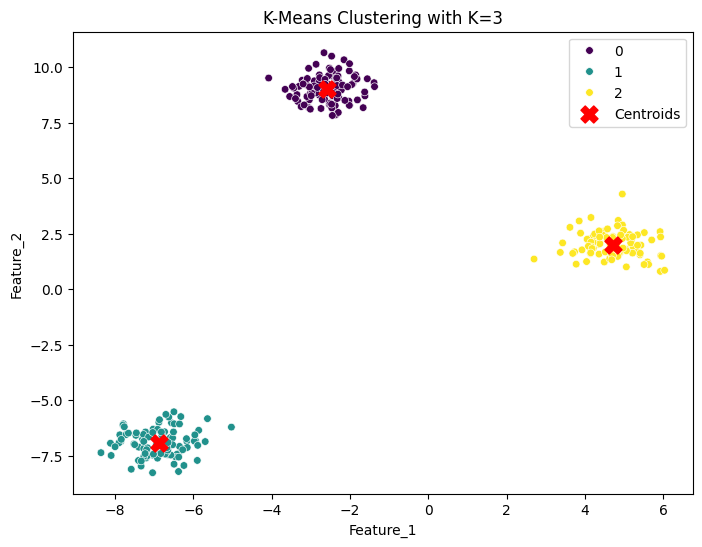


Silhouette Score for K-Means (K=3): 0.908

--- Part 2: Dimensionality Reduction with PCA ---

Original PCA Dataset Head:
   Feature_1  Feature_2  Feature_3  Feature_4  True_Cluster
0  -0.638667   1.110057  -6.400722  -0.204990             3
1  -2.951556  -7.657445   3.844794   0.903589             1
2  -0.253177   2.125103  -7.869801   0.559678             3
3  -2.151209   3.401400  -5.734930   0.965230             3
4  -2.347519  -7.230467   3.478891  -0.443440             1

Original PCA Dataset Shape: (500, 5)

Principal Components Head:
   Principal_Component_1  Principal_Component_2  True_Cluster
0               0.455305               1.623917             3
1              -2.705622               0.375012             1
2               0.810234               1.966926             3
3               0.427139               2.149626             3
4              -2.407508               0.099250             1

Explained Variance Ratio: [0.57208431 0.33622342]
Total Explained Variance by 2

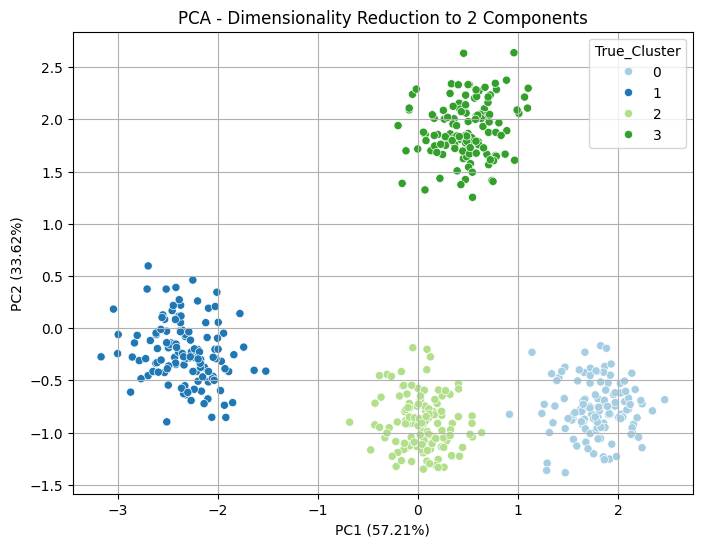

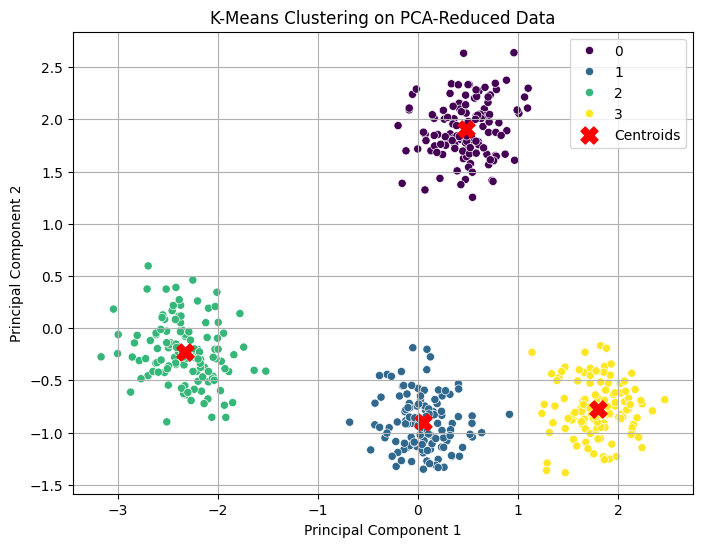


Silhouette Score for K-Means on PCA-Reduced Data (K=4): 0.776


In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# =====================================================
# PART 1 : K-MEANS CLUSTERING
# =====================================================

print("--- Part 1: K-Means Clustering ---")

# Generate Dataset
X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=0.60,
    random_state=42
)

df_kmeans = pd.DataFrame(
    X,
    columns=["Feature_1","Feature_2"]
)

print("\nOriginal K-Means Dataset Head:")
print(df_kmeans.head())

# -------------------------
# Elbow Method
# -------------------------

wcss = []

for i in range(1,11):

    kmeans = KMeans(
        n_clusters=i,
        init="k-means++",
        max_iter=300,
        n_init=10,
        random_state=42
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(
    range(1,11),
    wcss,
    marker='o',
    linestyle='--'
)

plt.title("Elbow Method for Optimal K (K-Means)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)

plt.show()

# -------------------------
# Apply KMeans
# -------------------------

optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    max_iter=300,
    n_init=10,
    random_state=42
)

clusters = kmeans.fit_predict(X)

df_kmeans["Cluster"] = clusters

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_kmeans,
    x="Feature_1",
    y="Feature_2",
    hue="Cluster",
    palette="viridis",
    s=30
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    c="red",
    marker="X",
    s=150,
    label="Centroids"
)

plt.title("K-Means Clustering with K=3")
plt.legend()

plt.show()

silhouette_avg = silhouette_score(X,clusters)

print(f"\nSilhouette Score for K-Means (K=3): {silhouette_avg:.3f}")

# =====================================================
# PART 2 : PCA
# =====================================================

print("\n--- Part 2: Dimensionality Reduction with PCA ---")

# Generate 4D Dataset

X_pca, y_pca = make_blobs(
    n_samples=500,
    n_features=4,
    centers=4,
    cluster_std=1.0,
    random_state=25
)

df_original = pd.DataFrame(
    X_pca,
    columns=[
        "Feature_1",
        "Feature_2",
        "Feature_3",
        "Feature_4"
    ]
)

df_original["True_Cluster"] = y_pca

print("\nOriginal PCA Dataset Head:")
print(df_original.head())

print("\nOriginal PCA Dataset Shape:",df_original.shape)

# -------------------------
# Standardization
# -------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_pca)

# -------------------------
# PCA
# -------------------------

pca = PCA(n_components=2)

principal_components = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(
    principal_components,
    columns=[
        "Principal_Component_1",
        "Principal_Component_2"
    ]
)

df_pca["True_Cluster"] = y_pca

print("\nPrincipal Components Head:")
print(df_pca.head())

print("\nExplained Variance Ratio:",pca.explained_variance_ratio_)

print(
    "Total Explained Variance by 2 PCs:",
    round(sum(pca.explained_variance_ratio_),3)
)

# -------------------------
# PCA Plot
# -------------------------

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_pca,
    x="Principal_Component_1",
    y="Principal_Component_2",
    hue="True_Cluster",
    palette="Paired",
    s=35
)

plt.title("PCA - Dimensionality Reduction to 2 Components")

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

plt.grid(True)

plt.show()

# -------------------------
# KMeans on PCA Data
# -------------------------

kmeans_pca = KMeans(
    n_clusters=4,
    init="k-means++",
    max_iter=300,
    n_init=10,
    random_state=42
)

clusters_pca = kmeans_pca.fit_predict(principal_components)

df_pca["KMeans_Cluster"] = clusters_pca

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_pca,
    x="Principal_Component_1",
    y="Principal_Component_2",
    hue="KMeans_Cluster",
    palette="viridis",
    s=35
)

plt.scatter(
    kmeans_pca.cluster_centers_[:,0],
    kmeans_pca.cluster_centers_[:,1],
    c="red",
    marker="X",
    s=150,
    label="Centroids"
)

plt.title("K-Means Clustering on PCA-Reduced Data")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()

plt.grid(True)

plt.show()

silhouette_avg_pca = silhouette_score(
    principal_components,
    clusters_pca
)

print(
    f"\nSilhouette Score for K-Means on PCA-Reduced Data (K=4): {silhouette_avg_pca:.3f}"
)